# Шаг 3. Многослойная сеть учится узнавать все 10 цифр

Один нейрон умеет только «да/нет». Для десяти цифр соберём **многослойную сеть** (MLP, *multilayer perceptron*)
и обучим её с помощью библиотеки **PyTorch**, которая сама считает градиенты.

**Архитектура сети `MLP`** (из `common.py`):

| Слой | Что делает | Выход |
|------|------------|-------|
| `Flatten` | вытягивает картинку 1 × 28 × 28 в строку | 784 числа |
| `Linear(784, 128)` + `ReLU` | 128 нейронов, каждый смотрит на все 784 пикселя | 128 чисел |
| `Linear(128, 64)` + `ReLU` | 64 нейрона смотрят на выходы первого слоя | 64 числа |
| `Linear(64, 10)` | 10 выходов — «оценки» (logits) для цифр 0…9 | 10 чисел |

`ReLU(z) = max(0, z)` — простая нелинейность. Без неё несколько слоёв подряд схлопнулись бы в один линейный.
Ответ сети — номер выхода с наибольшей оценкой.

**Обучение — это повторение четырёх действий тысячи раз:**
посмотреть → посчитать ошибку → найти виноватые веса → чуть-чуть их подправить.

**Структура ноутбука (алгоритм):**
1. Импортируем PyTorch и помощники, фиксируем случайность.
2. Готовим загрузчик данных: обучающие картинки идут пачками по 64 штуки в случайном порядке.
3. Создаём сеть, считаем её веса и точность до обучения (~10% — угадывание).
4. Выбираем функцию ошибки (перекрёстная энтропия) и оптимизатор (Adam).
5. Обучаем 3 эпохи; после каждой печатаем ошибку и точность на проверке.
6. Сохраняем обученную сеть в `mlp.pt` — она нужна шагам 4, 5, 6.
7. Рисуем график падения ошибки и сохраняем в `loss_curve.png`.
8. Проверяем сеть на своей картинке цифры с Google Диска.

> Обучение займёт около минуты на обычном ноутбуке.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session03")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.MNIST(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех ноутбуках этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `mnist(train)` | скачивает (один раз, ~12 МБ в папку `data`) и возвращает набор MNIST: обучающий (`train=True`, 60 000) или проверочный (`train=False`, 10 000) |
| `MLP` | многослойная сеть: 784 входа → 128 → 64 → 10 выходов |
| `train(model, dataset, epochs)` | цикл обучения из шага 3, без пояснений |
| `predict_all(model, dataset)` | ответы сети (номер цифры) для каждой картинки набора |
| `accuracy(model, dataset)` | доля картинок, на которых сеть ответила верно |
| `load_model()` | загрузить обученную сеть из `mlp.pt` (файл создаёт шаг 3) |
| `show()` | показать графики matplotlib и закрыть их |
| `MODEL_FILE` | путь к файлу `mlp.pt` |

> Ноутбуки нужно запускать из папки `session03`, иначе `import common` не найдёт модуль.
> Нужные библиотеки: `pip install -r requirements.txt`.

## 1. Импорт и фиксация случайности

- `torch` — PyTorch: тензоры, автоматические градиенты, нейросети.
- `nn` — готовые слои и функции ошибки.
- `DataLoader` — нарезает набор данных на пачки (батчи) и перемешивает их.

`torch.manual_seed(0)` фиксирует генератор случайных чисел: начальные веса и порядок картинок
будут одинаковыми при каждом запуске, поэтому у всех получатся похожие числа.

In [1]:
import time

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader

from common import MLP, MODEL_FILE, accuracy, mnist, show

torch.manual_seed(0)  # чтобы у всех в классе получались похожие числа

## 2. Загрузчик данных

Обновлять веса после каждой картинки — слишком шумно, после всех 60 000 сразу — слишком медленно.
Компромисс — **мини-пачки** (`batch_size=64`): сеть смотрит на 64 картинки, усредняет ошибку и делает один шаг.
За одну эпоху получается `60 000 / 64 ≈ 938` шагов.

`shuffle=True` — в каждой эпохе картинки идут в новом случайном порядке, чтобы сеть не заучила последовательность.

In [2]:
train_loader = DataLoader(mnist(train=True), batch_size=64, shuffle=True)  # пачки по 64 картинки
test_set = mnist(train=False)

## 3. Создаём сеть

`print(model)` показывает слои. Число весов: `784·128 + 128 + 128·64 + 64 + 64·10 + 10 = 109 386`
(у каждого слоя `Linear` есть матрица весов и вектор смещений).

Начальные веса случайные, поэтому до обучения сеть отвечает наугад: точность около 10% (1 из 10).

In [3]:
model = MLP()
print(model)
print("Весов в сети:", sum(p.numel() for p in model.parameters()))
print(f"Точность до обучения: {accuracy(model, test_set):.1%} — просто угадывает")

MLP(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Весов в сети: 109386
Точность до обучения: 10.0% — просто угадывает


## 4. Функция ошибки и оптимизатор

- **`CrossEntropyLoss`** (перекрёстная энтропия) — мера ошибки для классификации. Внутри она превращает 10 оценок
  в вероятности (softmax) и берёт `−log(вероятность правильной цифры)`. Если сеть уверена в правильном ответе — ошибка около 0;
  если правильной цифре дала маленькую вероятность — ошибка большая.
- **`Adam`** — «умный» вариант градиентного спуска: подбирает величину шага для каждого веса отдельно
  и учитывает направление прошлых шагов (инерцию). `lr=0.001` — базовая скорость обучения.
  `model.parameters()` — список всех весов, которые оптимизатору разрешено менять.

In [16]:
loss_fn = nn.CrossEntropyLoss()                            # мера ошибки
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)  # кто подправляет веса

## 5. Цикл обучения

Внешний цикл — по **эпохам** (эпоха = один проход по всем 60 000 картинкам), внутренний — по пачкам.

`model.train()` переключает сеть в режим обучения (важно для некоторых слоёв; функция `accuracy` переключает её в `eval`).

Четыре действия на каждой пачке:
1. **Посмотреть**: `model(images)` — прямой проход, получаем оценки формы `(64, 10)`.
2. **Посчитать ошибку**: `loss_fn(predictions, labels)` — одно число, средняя ошибка по пачке.
3. **Найти виноватые веса**: `loss.backward()` — **обратное распространение ошибки**: PyTorch автоматически считает
   градиент ошибки по каждому из 109 386 весов. Перед этим `optimizer.zero_grad()` обнуляет старые градиенты —
   иначе PyTorch прибавил бы новые к прошлым.
4. **Подправить**: `optimizer.step()` — сдвигает каждый вес против его градиента.

Каждые 50 пачек запоминаем ошибку в `history` (`loss.item()` превращает тензор в обычное число) — для графика.
После каждой эпохи печатаем ошибку, точность на проверочных картинках и прошедшее время.

In [17]:
EPOCHS = 3  # эпоха = один проход по всем 60 000 картинкам
history = []
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    for step, (images, labels) in enumerate(train_loader):
        predictions = model(images)           # 1. посмотреть
        loss = loss_fn(predictions, labels)   # 2. посчитать ошибку
        optimizer.zero_grad()
        loss.backward()                       # 3. найти, какой вес в чём виноват
        optimizer.step()                      # 4. чуть-чуть подправить веса
        if step % 50 == 0:
            history.append(loss.item())
    print(f"Эпоха {epoch}: ошибка {loss.item():.3f}, "
          f"точность на проверке {accuracy(model, test_set):.1%}  ({time.time() - start:.0f} с)")

Эпоха 1: ошибка 0.001, точность на проверке 98.0%  (12 с)
Эпоха 2: ошибка 0.000, точность на проверке 98.0%  (23 с)
Эпоха 3: ошибка 0.000, точность на проверке 98.0%  (34 с)


## 6. Сохраняем сеть

`model.state_dict()` — словарь со всеми весами сети. `torch.save` записывает его в файл `mlp.pt`.
Следующие ноутбуки загрузят эти веса функцией `load_model()` и не будут обучать сеть заново.

In [12]:
torch.save(model.state_dict(), MODEL_FILE)
print(f"Сеть сохранена в {MODEL_FILE.name}")

Сеть сохранена в mlp.pt


## 7. График обучения

Каждая точка — ошибка на одной пачке (берём каждую 50-ю). Ошибка быстро падает в начале и потом медленно снижается.
График «шумный», потому что пачки разные: одни картинки проще, другие сложнее.

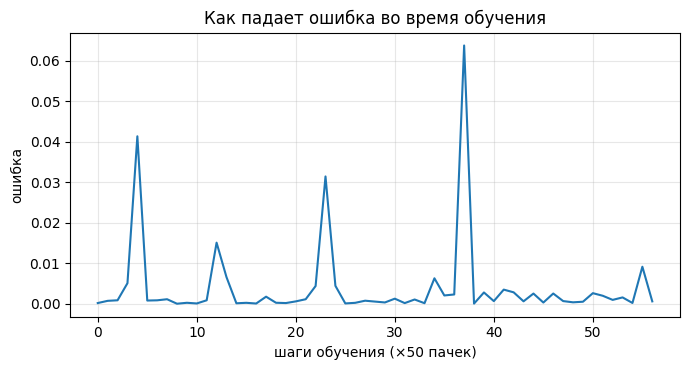

In [18]:
plt.figure(figsize=(7, 3.8))
plt.plot(history)
plt.xlabel("шаги обучения (×50 пачек)")
plt.ylabel("ошибка")
plt.title("Как падает ошибка во время обучения")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=100)
show()

## 8. Своя цифра с Google Диска

Самая честная проверка — на цифре, которую сеть никогда не видела: нарисуйте её сами.

**Как подготовить картинку:**
1. На белом листе нарисуйте **одну цифру** чёрным **толстым** маркером (тонкая ручка после уменьшения до 28 × 28 почти исчезнет).
2. Сфотографируйте лист сверху, при ровном свете, чтобы цифра занимала большую часть кадра.
   Можно и нарисовать цифру в Paint — белым по чёрному или чёрным по белому, неважно.
3. Загрузите файл на Google Диск **в корень «Мой диск»** (папка `MyDrive`):
   на [drive.google.com](https://drive.google.com) нажмите **«Создать» → «Загрузить файлы»**.
   В Colab это же можно сделать на панели «Файлы» слева: `drive/MyDrive` → «⋮» → «Загрузить».
4. Впишите имя файла в переменную `FILE_NAME` в ячейке ниже (по умолчанию `my_digit.png`; подходят `.png` и `.jpg`).

> На своём компьютере (без Colab) положите файл рядом с ноутбуком, в папку `session03`.

In [ ]:
from pathlib import Path

FILE_NAME = "my_digit.png"  # имя вашего файла в папке «Мой диск» (MyDrive)

try:
    from google.colab import drive
    drive.mount("/content/drive")  # если Диск уже подключён, просто напишет об этом
    digit_path = Path("/content/drive/MyDrive") / FILE_NAME
except ImportError:
    digit_path = Path(FILE_NAME)  # свой компьютер: файл рядом с ноутбуком

if not digit_path.exists():
    raise FileNotFoundError(
        f"Нет файла {digit_path}. Загрузите картинку на Google Диск в «Мой диск» (MyDrive) "
        "и проверьте имя в FILE_NAME — большие и маленькие буквы различаются."
    )
print("Нашли картинку:", digit_path)

### Готовим картинку «как в MNIST»

Сеть училась на картинках особого вида, и свою нужно привести к нему же, иначе она ответит наугад:

| В MNIST | Что делаем с фото |
|---------|-------------------|
| серые картинки | `.convert("L")` — один канал яркости вместо трёх цветов |
| **белая** цифра на **чёрном** фоне | если фон светлый (средняя яркость > 0.5) — инвертируем: `1 - x` |
| фон ровно 0 | растягиваем яркость на 0…1 и всё, что темнее порога `0.4`, считаем фоном |
| цифра вписана в квадрат 20 × 20 | вырезаем рамку вокруг цифры и уменьшаем до 20 пикселей по большей стороне |
| в центре картинки 28 × 28 стоит **центр масс** цифры | кладём на чёрный холст 28 × 28 и сдвигаем так, чтобы «средняя точка» белых пикселей оказалась в центре |
| числа от 0 до 1, тензор `(1, 1, 28, 28)` | делим на максимум и добавляем оси пачки и канала |

`ImageOps.exif_transpose` поворачивает фото с телефона так, как оно выглядит на экране
(телефон часто хранит снимок «на боку» и только записывает, как его повернуть).

Центр масс важен: сеть из одних `Linear` не умеет «искать» цифру на картинке — она ждёт её ровно там,
где цифры стояли при обучении. Сдвиг даже на 2–3 пикселя заметно портит ответы.

In [ ]:
import numpy as np
from PIL import Image, ImageOps


def prepare_digit(photo, threshold=0.4):
    """Фото цифры любого размера → массив 28×28 «как в MNIST»: белая цифра на чёрном, числа 0..1."""
    x = np.asarray(photo.convert("L"), dtype=np.float32) / 255  # серая картинка, 0 — чёрный, 1 — белый
    if x.mean() > 0.5:                                            # фон светлый → цифра тёмная
        x = 1 - x                                                 # инвертируем: белая цифра на чёрном
    x = (x - x.min()) / (x.max() - x.min() + 1e-6)                # растягиваем яркость на 0..1
    x[x < threshold] = 0                                          # серый фон бумаги → чистый чёрный

    rows = np.where(x.max(axis=1) > 0)[0]                         # строки и столбцы, где есть цифра
    cols = np.where(x.max(axis=0) > 0)[0]
    if len(rows) == 0:
        raise ValueError("Цифра не найдена: попробуйте уменьшить threshold или нарисовать её толще")
    x = x[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]             # рамка вокруг цифры

    h, w = x.shape
    scale = 20 / max(h, w)                                        # большая сторона → 20 пикселей
    new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
    small = Image.fromarray((x * 255).astype(np.uint8)).resize((new_w, new_h), Image.LANCZOS)

    canvas = np.zeros((28, 28), dtype=np.float32)                 # чёрный холст 28×28
    top, left = (28 - new_h) // 2, (28 - new_w) // 2
    canvas[top:top + new_h, left:left + new_w] = np.asarray(small, dtype=np.float32) / 255

    ys, xs = np.indices(canvas.shape)                             # центр масс: средняя точка белых пикселей
    dy = round(13.5 - (ys * canvas).sum() / canvas.sum())
    dx = round(13.5 - (xs * canvas).sum() / canvas.sum())
    canvas = np.roll(canvas, (dy, dx), axis=(0, 1))               # сдвигаем его в центр, как в MNIST
    return canvas / canvas.max()                                  # самая яркая точка = 1


photo = ImageOps.exif_transpose(Image.open(digit_path))
digit = prepare_digit(photo)
my_image = torch.from_numpy(digit).reshape(1, 1, 28, 28)  # пачка из 1 картинки, 1 канал
print("Размер фото:", photo.size, "→ тензор для сети:", tuple(my_image.shape))

### Ответ сети

`model(my_image)` возвращает 10 оценок (logits), `softmax` превращает их в вероятности, которые в сумме дают 1.
`model.eval()` и `torch.no_grad()` — режим «только ответить»: градиенты не нужны, сеть не учится.

Слева — ваше фото, в центре — то, что на самом деле видит сеть, справа — её уверенность в каждой цифре.
Сохраняем картинку в `my_digit_result.png`.

In [ ]:
model.eval()
with torch.no_grad():
    probs = torch.softmax(model(my_image), dim=1)[0]  # 10 вероятностей
best = probs.argmax().item()
print(f"Сеть думает, что это {best} (уверенность {probs[best].item():.0%})")
for d in probs.argsort(descending=True)[:3].tolist():
    print(f"  {d}: {probs[d].item():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1, 1, 1.6]})
axes[0].imshow(photo.convert("L"), cmap="gray")
axes[0].set_title("Ваше фото")
axes[1].imshow(digit, cmap="gray", interpolation="nearest")
axes[1].set_title("Что видит сеть (28×28)")
for ax in axes[:2]:
    ax.axis("off")
colors = ["#B8460A" if d == best else "#9AA5B1" for d in range(10)]
axes[2].bar(range(10), probs.numpy(), color=colors)
axes[2].set_xticks(range(10))
axes[2].set_ylim(0, 1)
axes[2].set_xlabel("цифра")
axes[2].set_title(f"Ответ сети: {best}")
plt.tight_layout()
plt.savefig("my_digit_result.png", dpi=100)
show()

## Попробуйте сами

1. Увеличьте `EPOCHS` до 10. Растёт ли точность дальше? Насколько?
2. Поменяйте `lr` на `0.1` и `0.00001`. Что происходит с графиком ошибки?
3. Поменяйте `batch_size` на 8 и 512. Как меняются скорость обучения и вид графика?
4. Уберите слои `ReLU` в `common.py` (оставив только `Linear`) и обучите заново. Какая получилась точность?
5. Нарисуйте одну и ту же цифру тонкой ручкой и толстым маркером, маленькой в углу листа и крупной.
   Когда сеть ошибается? Сравните картинку «что видит сеть» с картинками MNIST из шага 1.